### [Buoc 1] Kiem tra cau hinh GPU duoc cap phat


In [ ]:
!nvidia-smi


Mon Nov  9 03:03:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### [Buoc 2] Ket noi Google Drive


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

drive_dataset = '/content/drive/MyDrive/dataset_clean'
if os.path.exists(drive_dataset):
    print('Ket noi Google Drive thanh cong. Da tim thay thu muc: ' + drive_dataset)
else:
    print('Canh bao: Chua tim thay thu muc dataset_clean tren Google Drive. Vui long kiem tra lai ten thu muc tren MyDrive!')


Mounted at /content/drive
Ket noi Google Drive thanh cong. Da tim thay thu muc: /content/drive/MyDrive/dataset_clean


### [Buoc 3] Tai ma nguon YOLOv5 va cai dat thu vien


In [ ]:
%cd /content
!rm -rf yolov5
!git clone https://github.com/ultralytics/yolov5.git
%cd /content/yolov5

# Cai dat cac thu vien can thiet
%pip install -qr requirements.txt
%pip install -q pandas matplotlib seaborn pyyaml

# Tat bang hoi wandb
%env WANDB_MODE=disabled

# Xu ly tuong thich cho file utils/plots.py
!python -c "import re; p='utils/plots.py'; c=open(p, encoding='utf-8').read(); c=c.replace('annotator.im.save(fname)', 'cv2.imwrite(str(fname), np.asarray(annotator.im)[:, :, ::-1]) if not hasattr(annotator.im, \"save\") else annotator.im.save(fname)'); open(p, 'w', encoding='utf-8').write(c)"

import torch
from IPython.display import Image, display
print(f"Cai dat hoan tat. PyTorch {torch.__version__} - CUDA: {torch.cuda.is_available()}")


/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18881, done.
remote: Counting objects: 100% (415/415), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 18881 (delta 353), reused 339 (delta 339), pack-reused 18466 (from 2)
Receiving objects: 100% (18881/18881), 17.70 MiB | 15.39 MiB/s, done.
Resolving deltas: 100% (12888/12888), done.
/content/yolov5
env: WANDB_MODE=disabled
Cai dat hoan tat. PyTorch 2.14.1+cu130 - CUDA: True


### [Buoc 4] Nap du lieu tu Google Drive va cau hinh fire.yaml
Sao chep thu muc dataset_clean tu Google Drive sang o dia tam /content/dataset_clean de toi uu toc do I/O khi huan luyen va tao file cau hinh fire.yaml.


In [ ]:
import os
import shutil

DRIVE_DIR = '/content/drive/MyDrive/dataset_clean'
TARGET_DIR = '/content/dataset_clean'

if not os.path.exists(DRIVE_DIR):
    raise FileNotFoundError('Khong tim thay thu muc /content/drive/MyDrive/dataset_clean tren Google Drive!')

print('Dang sao chep thu muc dataset_clean tu Google Drive sang o dia Colab...')
# Xoa thu muc cu neu co de dam bao sach se
if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

# Sao chep du lieu sang o dia /content/ de doc ghi nhanh hon gap 3-5 lan
!cp -r /content/drive/MyDrive/dataset_clean /content/dataset_clean

print('\nNap du lieu hoan tat thanh cong:')
for split in ['train', 'val', 'test']:
    split_dir = f'{TARGET_DIR}/{split}/images'
    cnt = len(os.listdir(split_dir)) if os.path.exists(split_dir) else 0
    print(f'- Tap {split.capitalize()}: {cnt} anh')

# Tao file cau hinh fire.yaml
yaml_text = """
path: /content/dataset_clean
train: train/images
val: val/images
test: test/images

nc: 1
names: ['fire']
"""
with open('/content/yolov5/fire.yaml', 'w') as f:    f.write(yaml_text.strip())

print('\nFile fire.yaml da duoc tao thanh cong:')
!cat /content/yolov5/fire.yaml


Dang sao chep thu muc dataset_clean tu Google Drive sang o dia Colab...

Nap du lieu hoan tat thanh cong:
- Tap Train: 2573 anh
- Tap Val: 551 anh
- Tap Test: 553 anh

File fire.yaml da duoc tao thanh cong:
path: /content/dataset_clean
train: train/images
val: val/images
test: test/images

nc: 1
names: ['fire']

### [Buoc 5] THI NGHIEM 1: BASELINE MODEL (YOLOv5s Mac Dinh)
Chay 30 epochs, kich thuoc anh 640x640, luu ket qua tai: runs/train/exp1_baseline


In [ ]:
!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 30 \
  --data fire.yaml \
  --weights yolov5s.pt \
  --name exp1_baseline \
  --workers 2 \
  --cache


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1794193800.129153    8665 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=fire.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=runs/train, nam

### [Buoc 6] Danh gia ket qua Thi nghiem 1
Hien thi bieu do huan luyen va ma tran nham lan (Confusion Matrix).


BIEU DO KET QUA THI NGHIEM 1 (BASELINE):


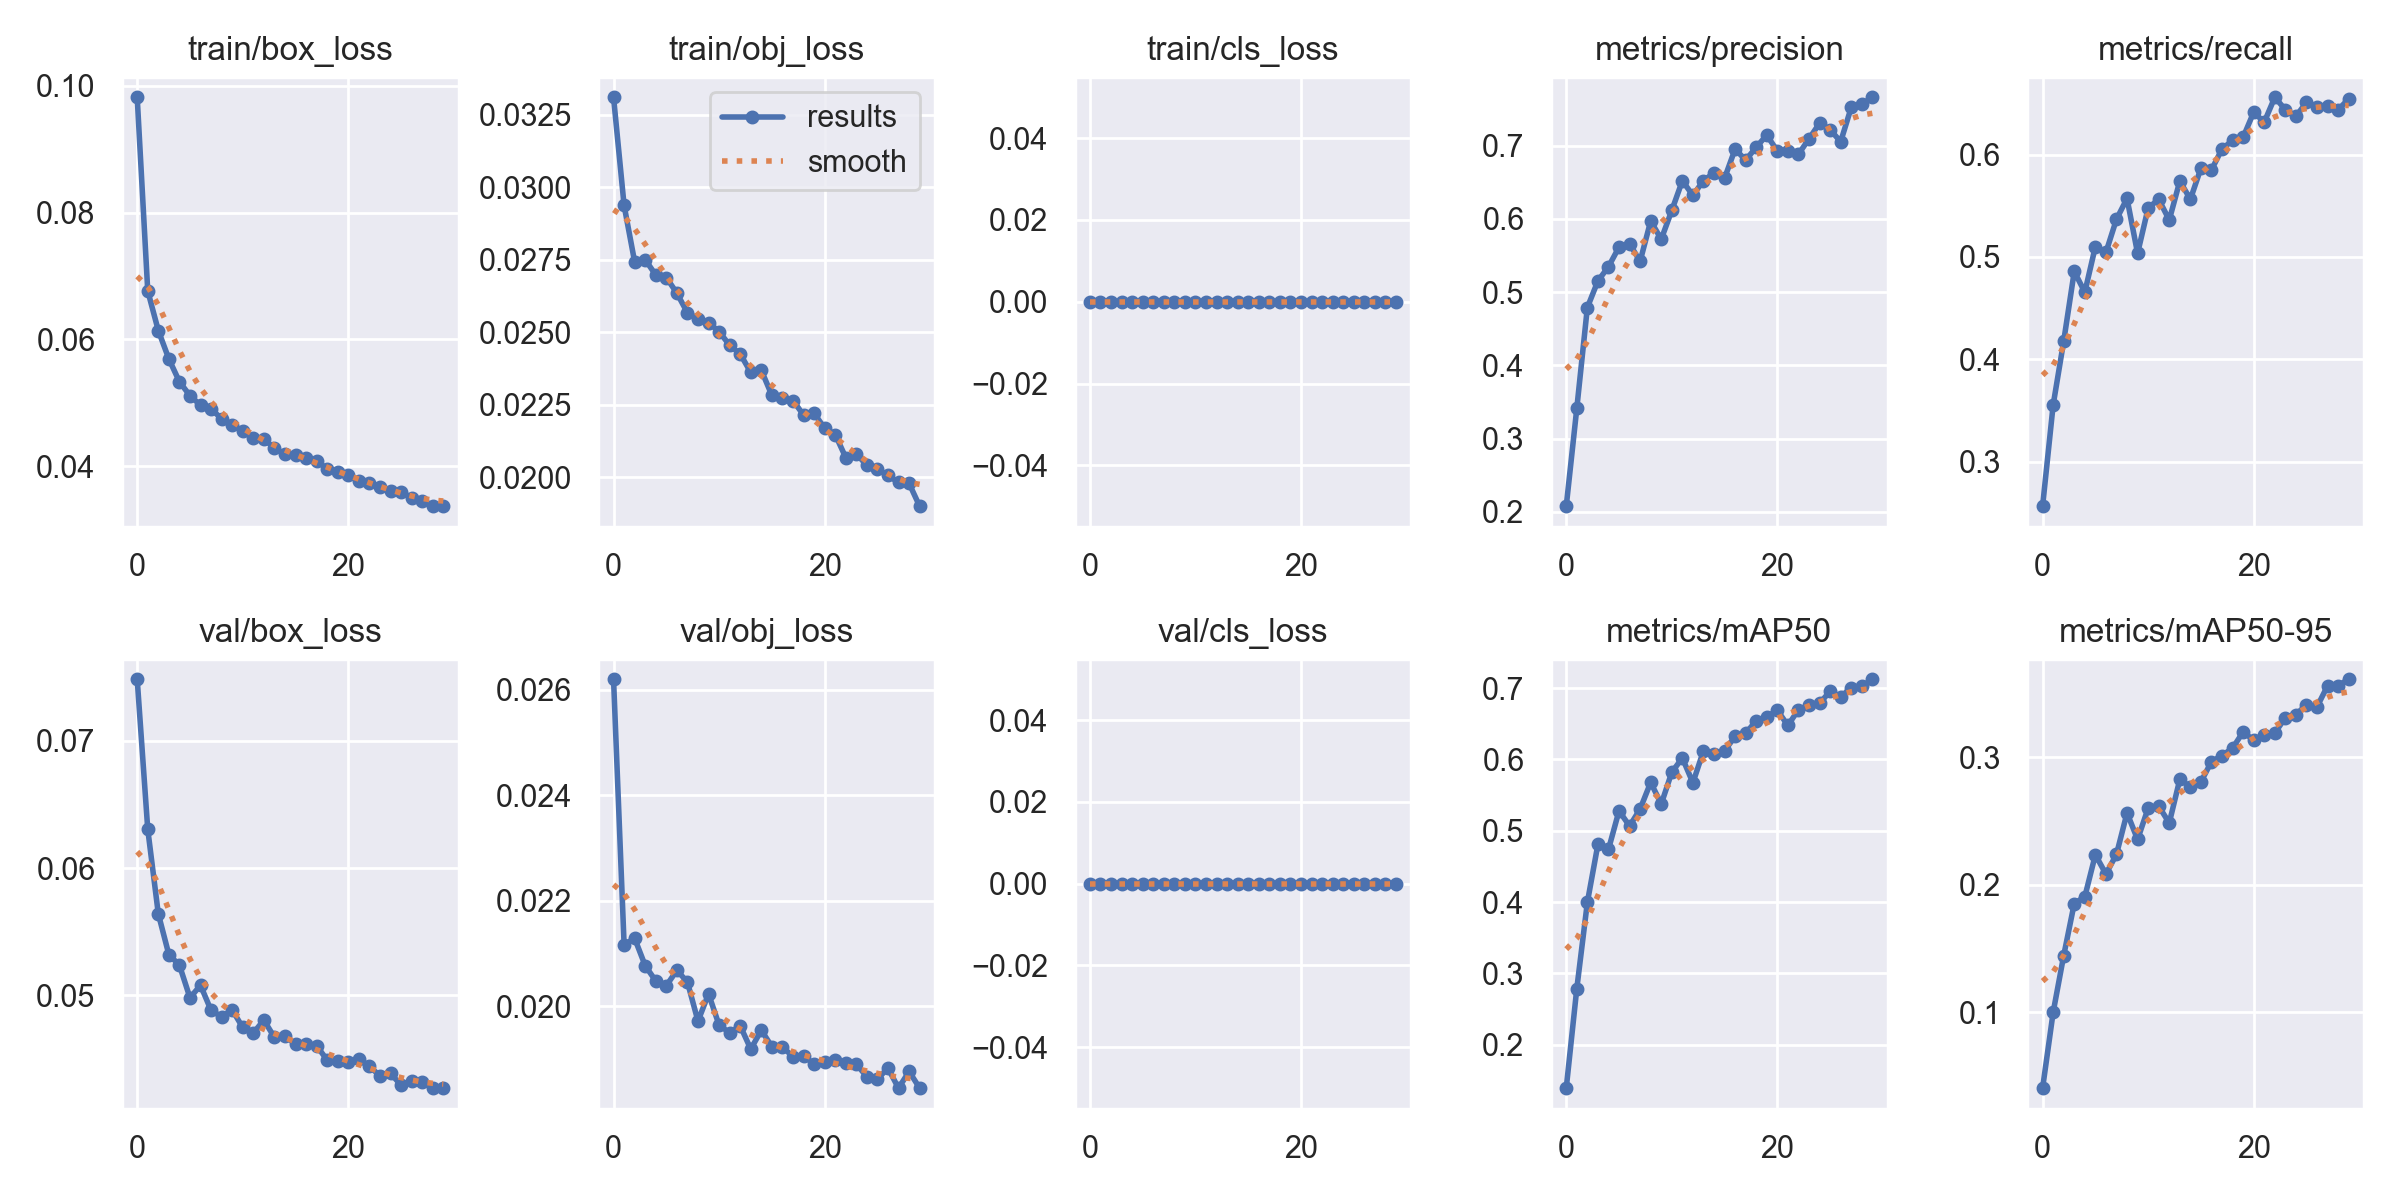

MA TRAN NHAM LAN (CONFUSION MATRIX):


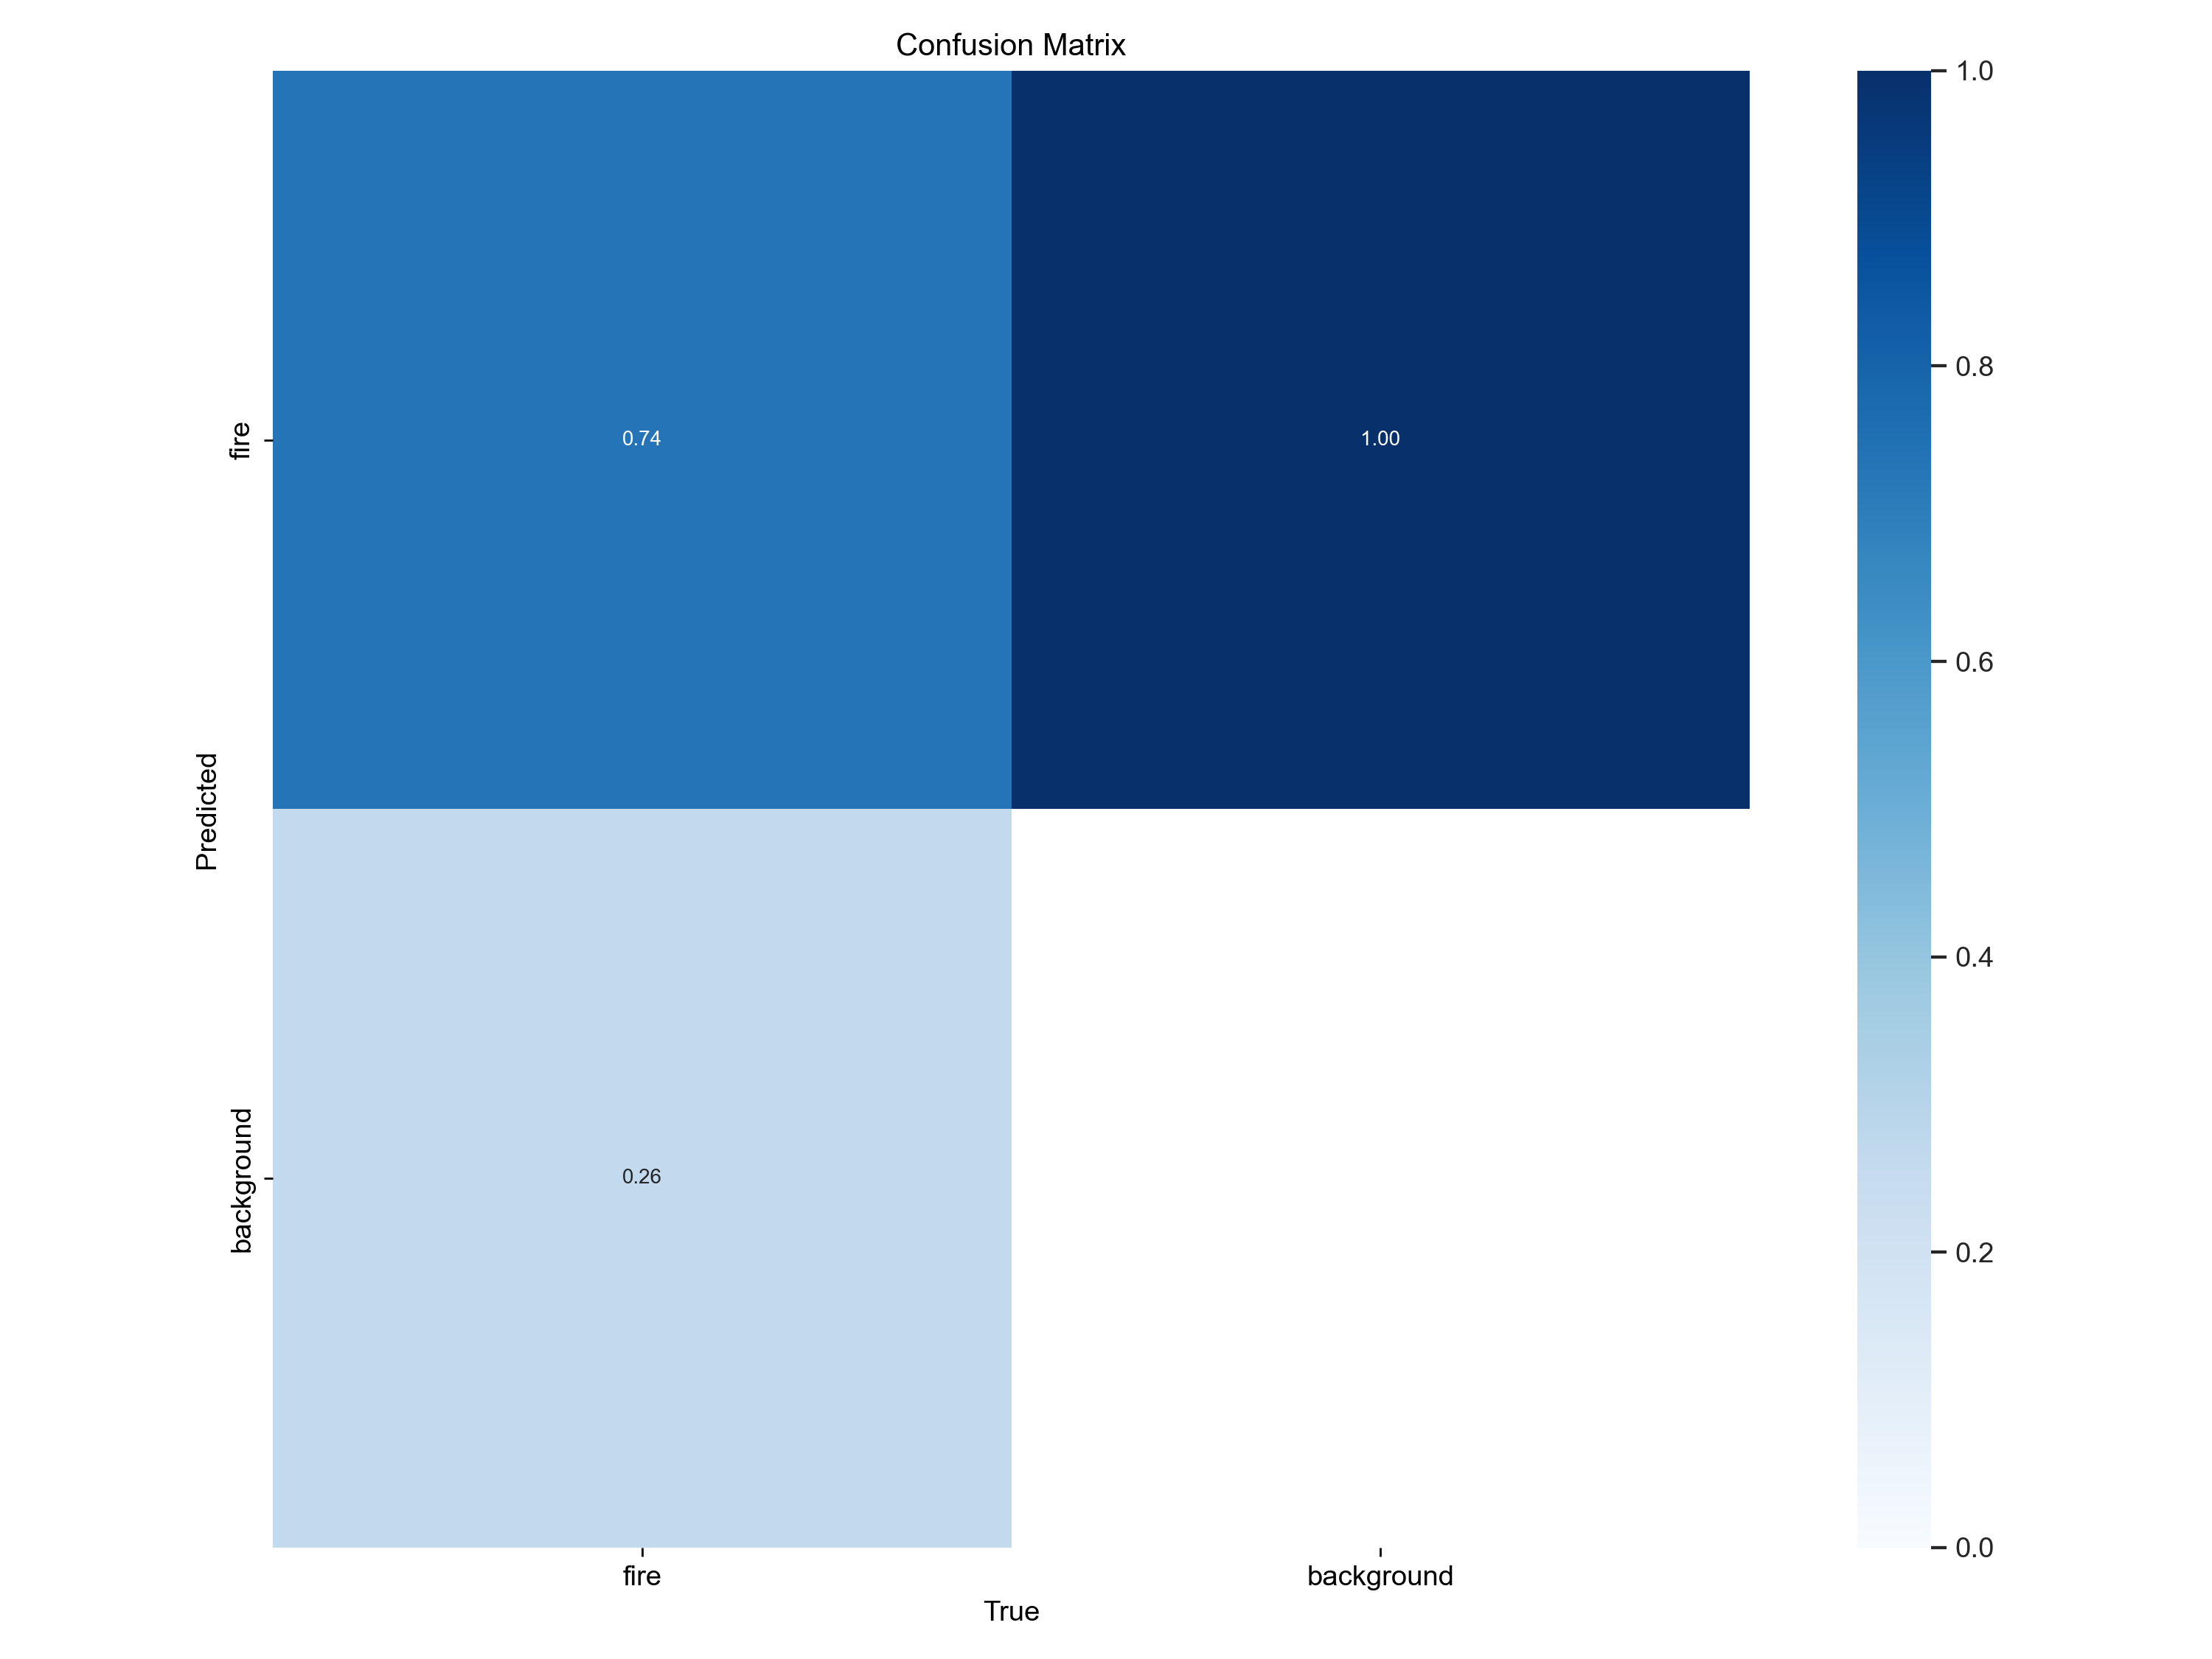

In [ ]:
print("BIEU DO KET QUA THI NGHIEM 1 (BASELINE):")
display(Image('runs/train/exp1_baseline/results.png', width=900))

print("MA TRAN NHAM LAN (CONFUSION MATRIX):")
display(Image('runs/train/exp1_baseline/confusion_matrix.png', width=600))


# Nhan xet
1. Danh gia ket qua

Mo hinh da nhan dien duoc doi tuong fire voi ty le khoang 74%.

Con khoang 26% doi tuong fire bi bo sot.

Ty le background bi nhan nham thanh fire la 100% theo ma tran chuan hoa, cho thay kha nang phan biet giua lua va moi truong xung quanh con kem.

Mo hinh chua du on dinh de trien khai thuc te do nguy co canh bao chay gia cao.


### [Buoc 7] THI NGHIEM 2: TINH CHINH THAM SO (EXP2_TUNING)
Dua tren chan doan o Thi nghiem 1, tien hanh tinh chinh:
- Giam learning rate ban dau (lr0 = 0.005) de mo hinh hoi tu min hon.
- Giam cuong do mosaic xuong 0.7 va tat mixup (0.0) de giu nguyen ven dac trung lua.
- Tang kich thuoc anh len 768x768 de phat hien tot hon cac dom lua nho o xa.
- Bat Cosine Learning Rate Scheduler (--cos-lr) va Early Stopping (--patience 20).
Luu ket qua tai: runs/train/exp2_tuning


In [ ]:
import yaml

hyp_path = "data/hyps/hyp.scratch-low.yaml"

with open(hyp_path, "r") as f:
    hyp = yaml.safe_load(f)

hyp["lr0"] = 0.005
hyp["lrf"] = 0.01
hyp["mosaic"] = 0.7
hyp["mixup"] = 0.0

with open("hyp_fire.yaml", "w") as f:
    yaml.safe_dump(hyp, f, sort_keys=False)

print("Da tao file cau hinh sieu tham so hyp_fire.yaml thanh cong.")


Da tao file cau hinh sieu tham so hyp_fire.yaml thanh cong.


In [ ]:
!python train.py \
  --img 768 \
  --batch 16 \
  --epochs 40 \
  --data fire.yaml \
  --weights yolov5s.pt \
  --hyp hyp_fire.yaml \
  --name exp2_tuning \
  --workers 2 \
  --cache \
  --cos-lr \
  --patience 20


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1794195372.233703   15548 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=fire.yaml, hyp=hyp_fire.yaml, epochs=40, batch_size=16, imgsz=768, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=runs/train, name=exp2_tuning, exist_ok=False, quad=False, cos_lr=True, label_smoothing=0.0, patience=20, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-570-gcb2f17fd Python-3.13.16 torch-2.1

### [Buoc 8] BANG SO SANH HIEU NANG DAY DU (P, R, F1-SCORE, mAP) CHO BAO CAO
Trich xuat so lieu tu file results.csv cua ca 2 thi nghiem: exp1_baseline va exp2_tuning.


BANG SO SANH HIEU NANG GIUA 2 THI NGHIEM:


,Thi nghiem,Best Epoch,Precision,Recall,F1-Score (%),mAP@0.5 (%),mAP@0.5:0.95 (%),Val Box Loss,Val Obj Loss
0,exp1_baseline,29,0.7662,0.6545,70.59,71.24,36.12,0.0427,0.0184
1,exp2_tuning,37,0.7218,0.6837,70.22,70.83,37.20,0.0411,0.0197



So sanh bieu do ket qua huan luyen:
--> Bieu do Exp 1 (Baseline):


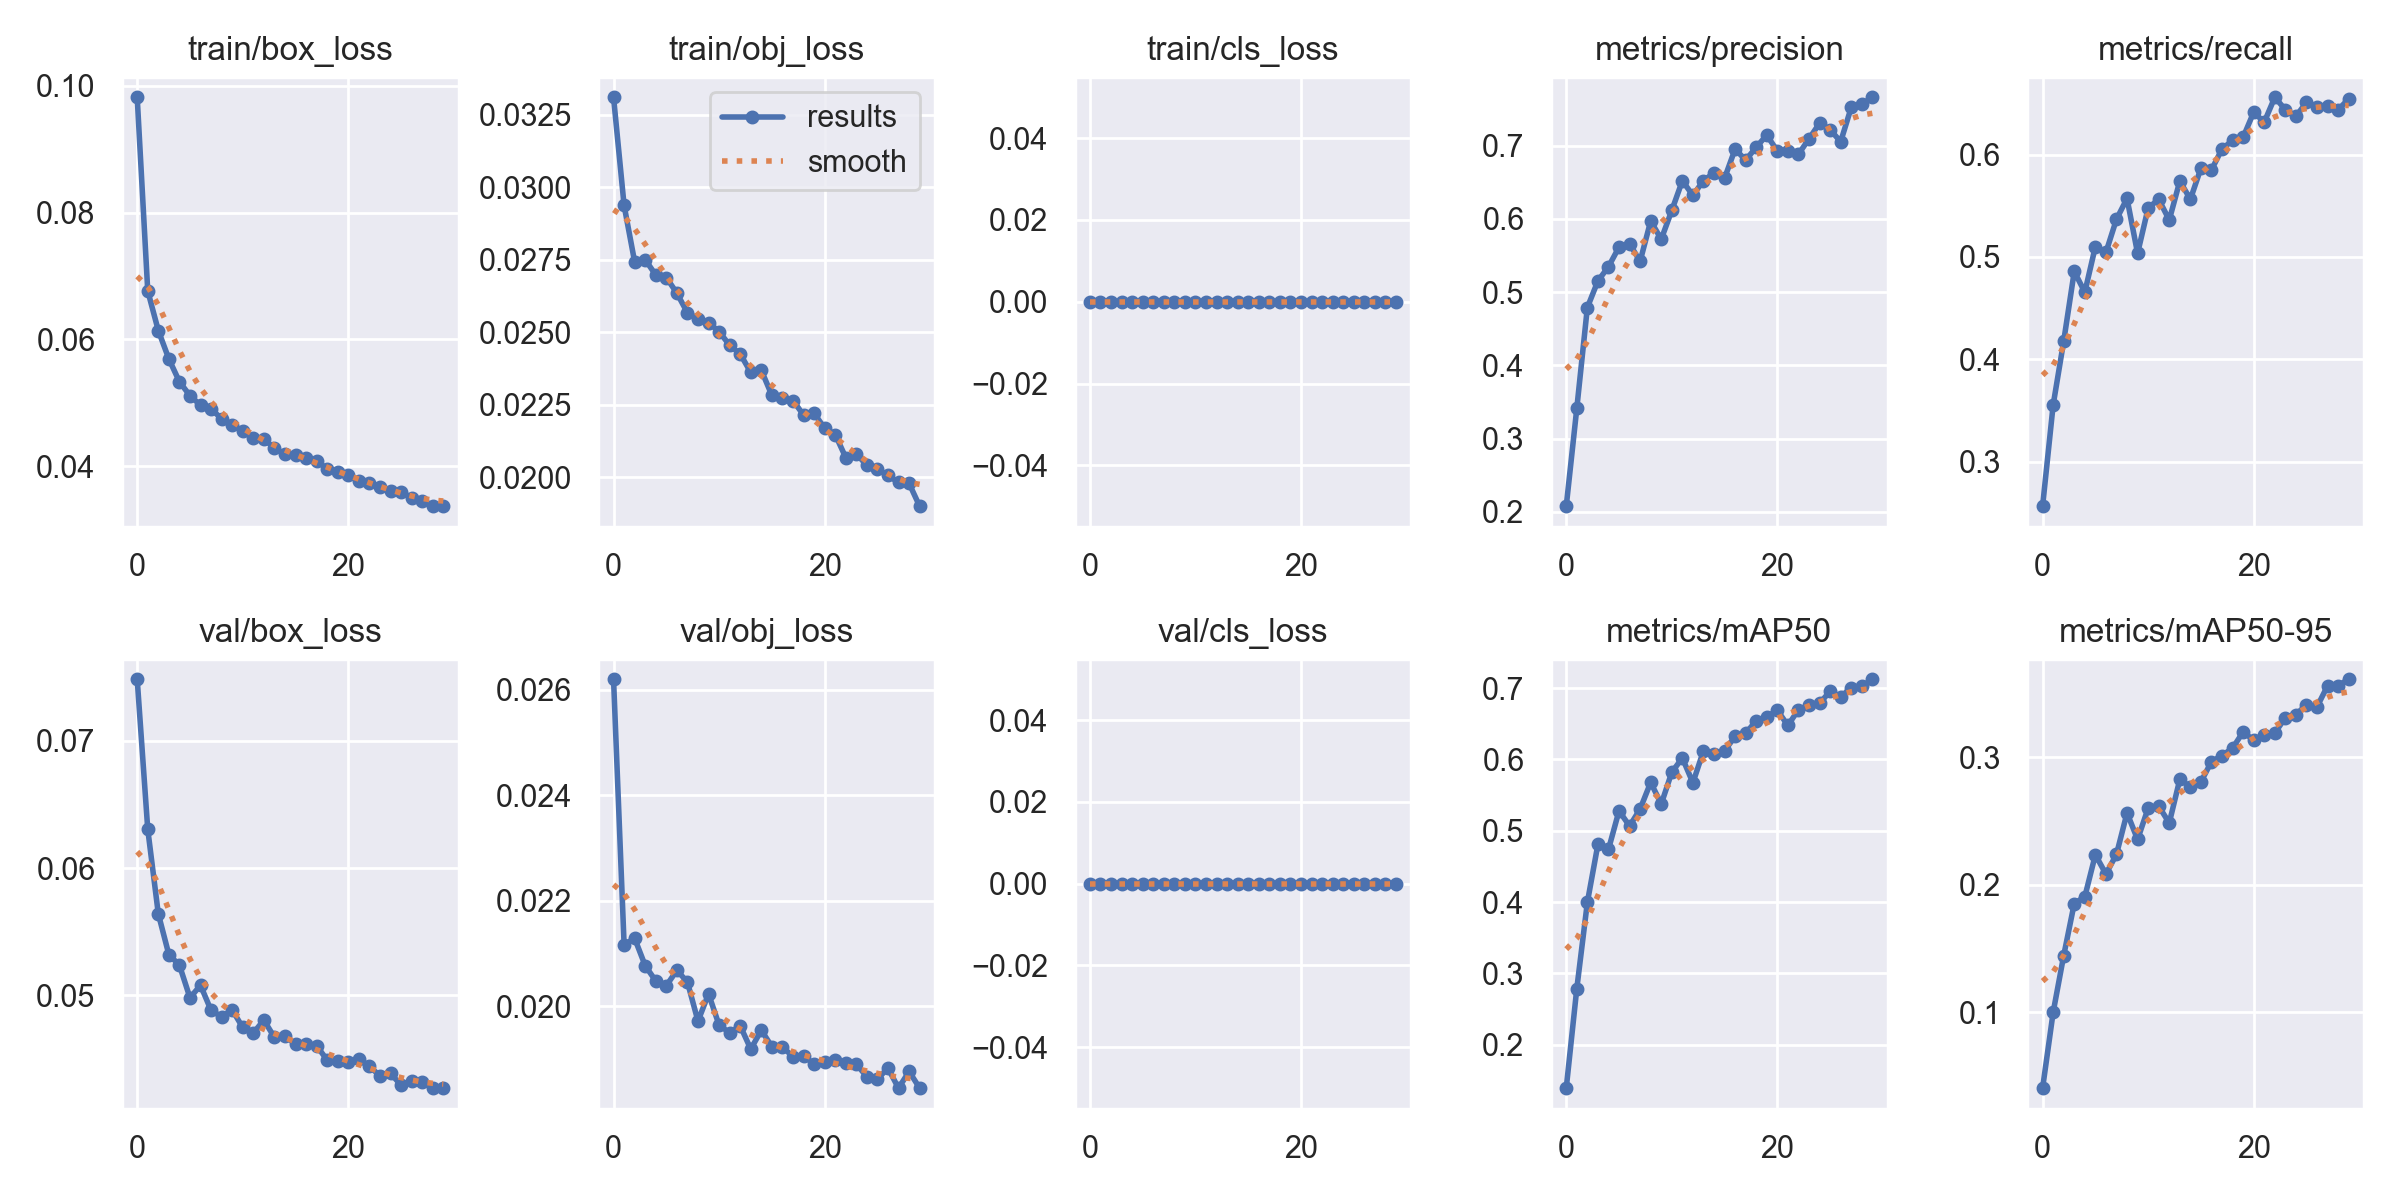

--> Bieu do Exp 2 (Tuning):


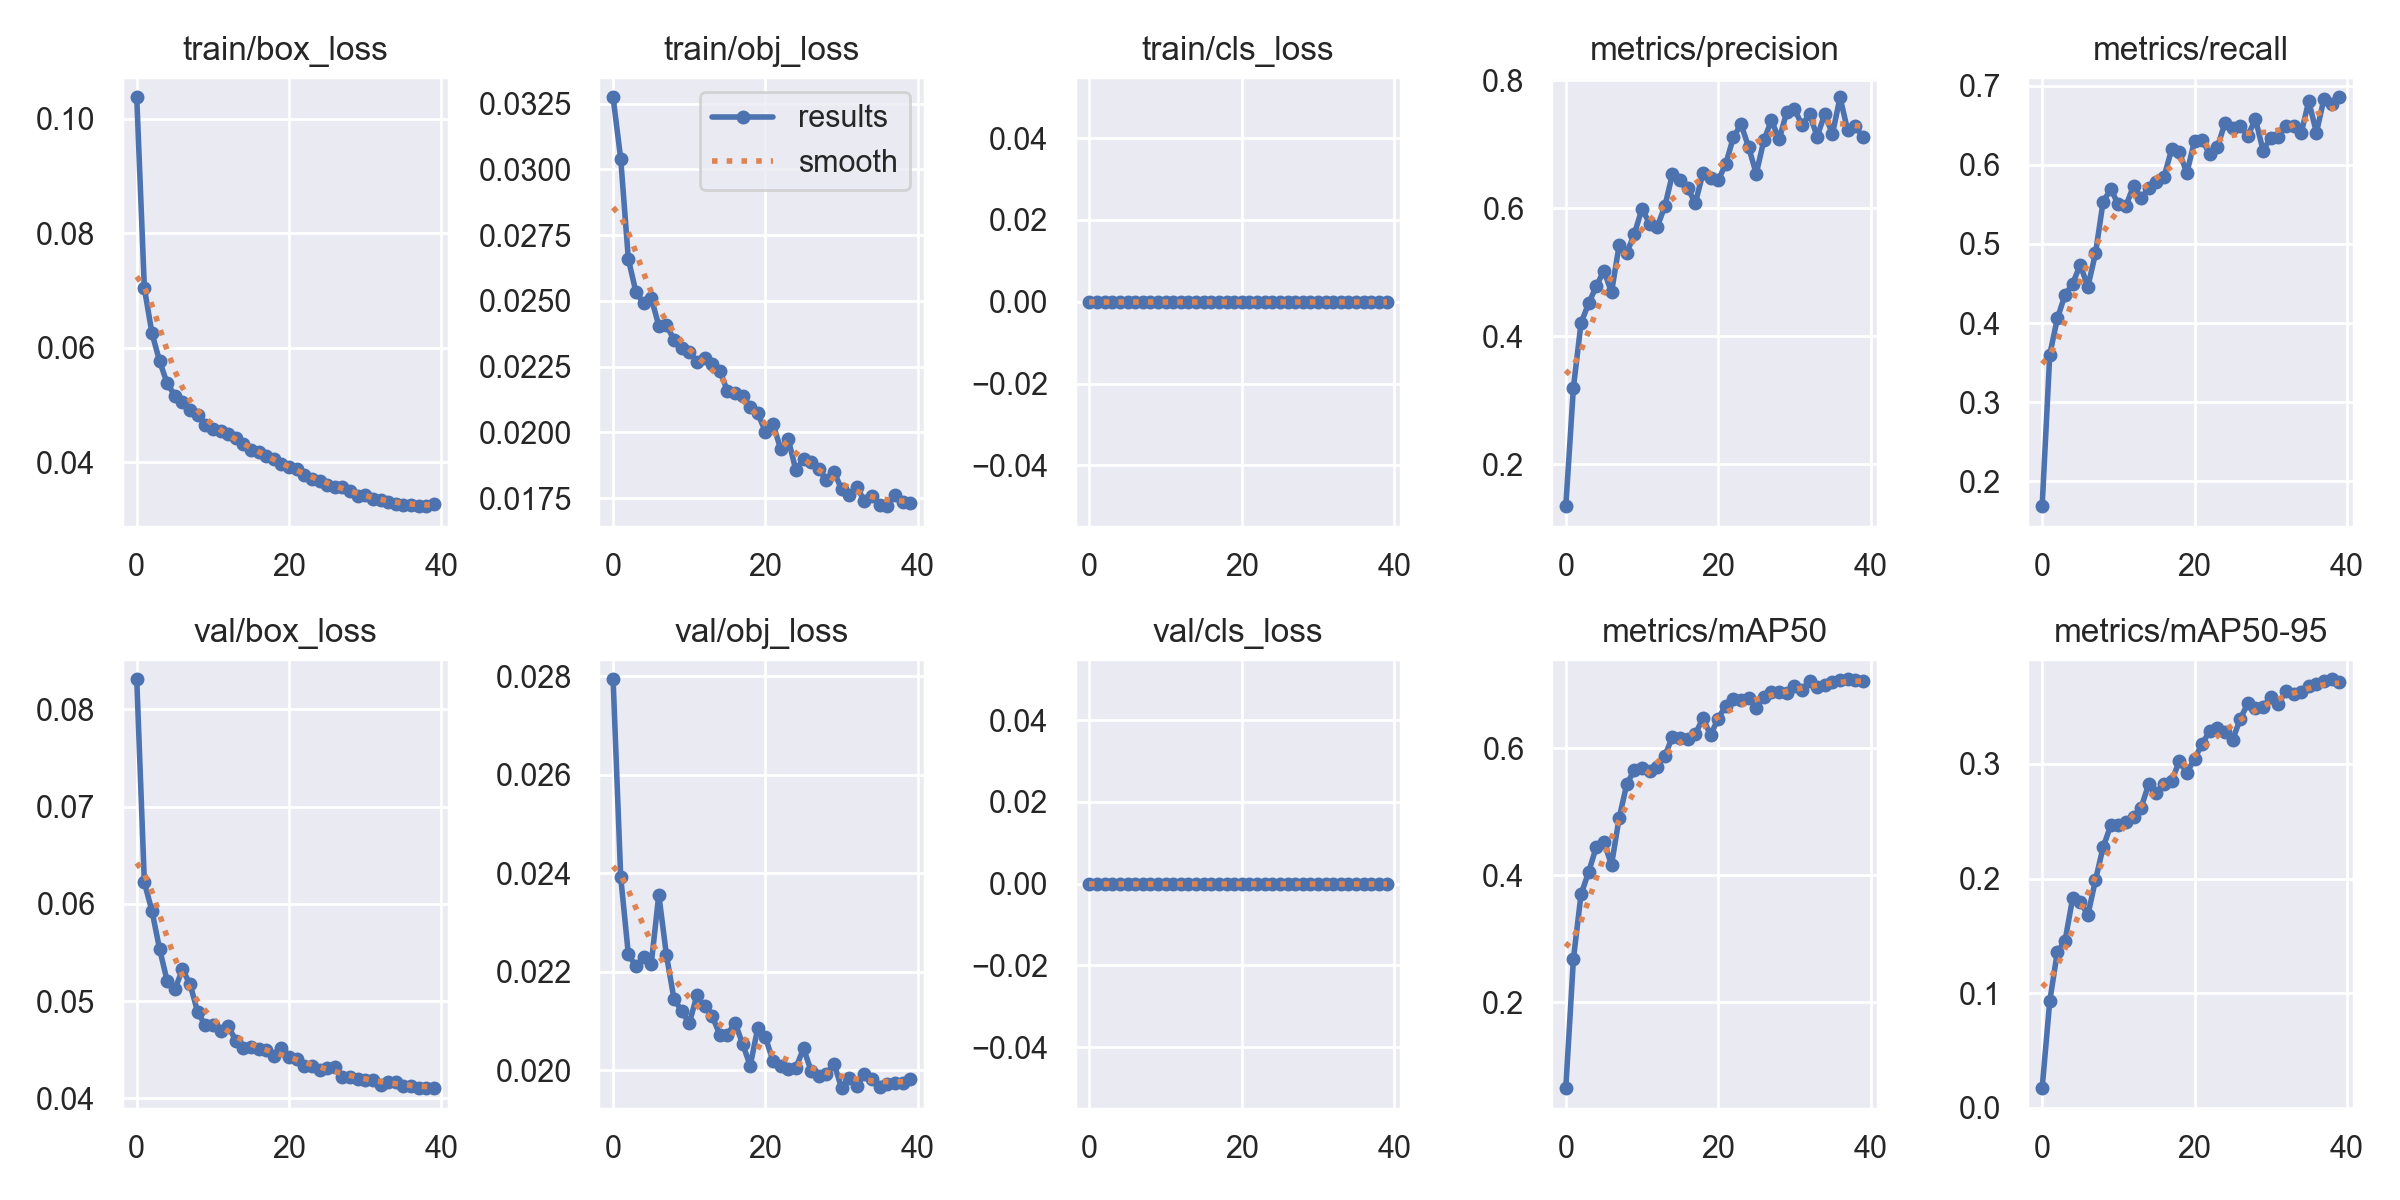

In [ ]:
import pandas as pd
import os

def get_best_metrics(exp_name):
    csv_path = f'runs/train/{exp_name}/results.csv'
    if not os.path.exists(csv_path):
        return None
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    # Lay dong co mAP50 cao nhat
    col_map50 = 'metrics/mAP50' if 'metrics/mAP50' in df.columns else 'metrics/mAP_0.5'
    col_map95 = 'metrics/mAP50-95' if 'metrics/mAP50-95' in df.columns else 'metrics/mAP_0.5:0.95'
    col_p = 'metrics/precision'
    col_r = 'metrics/recall'

    best_row = df.loc[df[col_map50].idxmax()]
    p = best_row[col_p]
    r = best_row[col_r]
    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0

    return {
        'Thi nghiem': exp_name,
        'Best Epoch': int(best_row['epoch']),
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1-Score (%)': round(f1 * 100, 2),
        'mAP@0.5 (%)': round(best_row[col_map50] * 100, 2),
        'mAP@0.5:0.95 (%)': round(best_row[col_map95] * 100, 2),
        'Val Box Loss': round(best_row['val/box_loss'], 4),
        'Val Obj Loss': round(best_row['val/obj_loss'], 4)
    }

results = []
for exp in ['exp1_baseline', 'exp2_tuning']:
    m = get_best_metrics(exp)
    if m:
        results.append(m)

summary_df = pd.DataFrame(results)
print("=" * 80)
print("BANG SO SANH HIEU NANG GIUA 2 THI NGHIEM:")
print("=" * 80)
display(summary_df)

print("\nSo sanh bieu do ket qua huan luyen:")
col1_path = 'runs/train/exp1_baseline/results.png'
col2_path = 'runs/train/exp2_tuning/results.png'
if os.path.exists(col1_path):
    print("--> Bieu do Exp 1 (Baseline):")
    display(Image(col1_path, width=750))
if os.path.exists(col2_path):
    print("--> Bieu do Exp 2 (Tuning):")
    display(Image(col2_path, width=750))


### [Buoc 9] Danh gia va suy luan (Inference) tren tap TEST doc lap (553 anh)
Tu dong lua chon mo hinh co chi so mAP cao nhat giua Exp 1 va Exp 2 de thuc hien kiem thu.


mAP@0.5 Exp 1: 71.24% | Exp 2: 70.83%
Mo hinh dat do chinh xac cao nhat: Exp 1 (Baseline)
Duong dan mo hinh: runs/train/exp1_baseline/weights/best.pt
val: data=fire.yaml, weights=['runs/train/exp1_baseline/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.25, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=eval_test_set, exist_ok=False, half=False, dnn=False
WARNING ⚠️ confidence threshold 0.25 > 0.001 produces invalid results
YOLOv5 🚀 v7.0-570-gcb2f17fd Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/dataset_clean/test/labels... 553 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 553/553 364.0it/s 1.5s
test: New cache created: /content/dataset_clean/test/labels.cache
                 Class     Ima

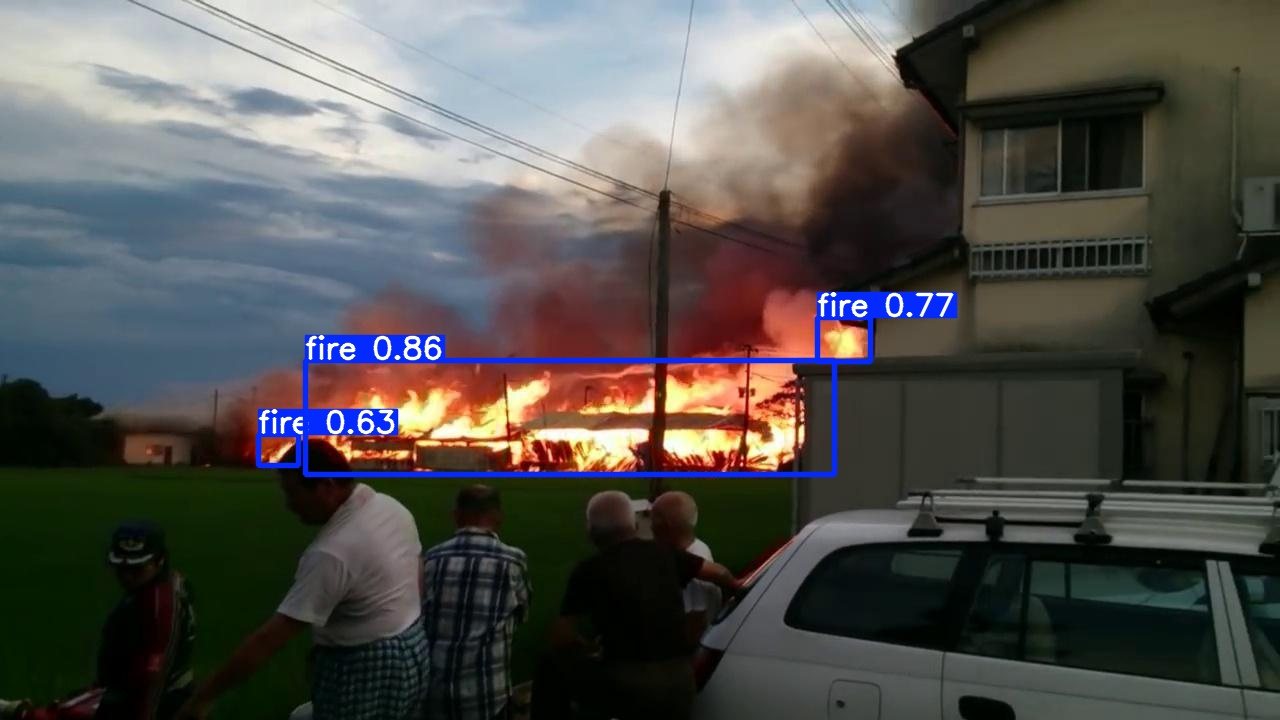

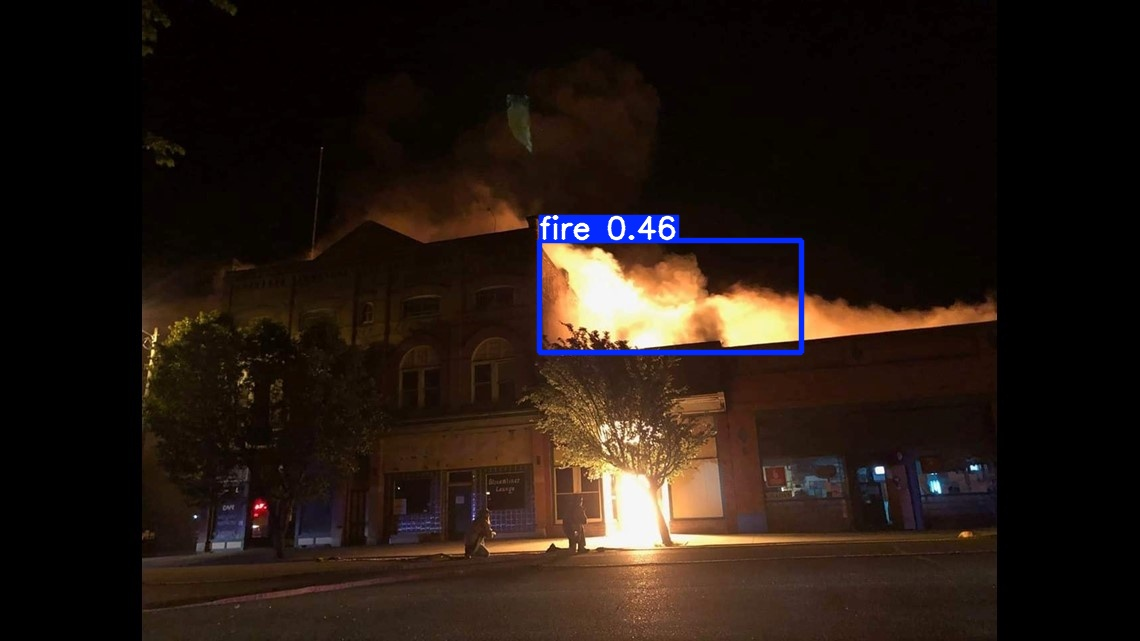

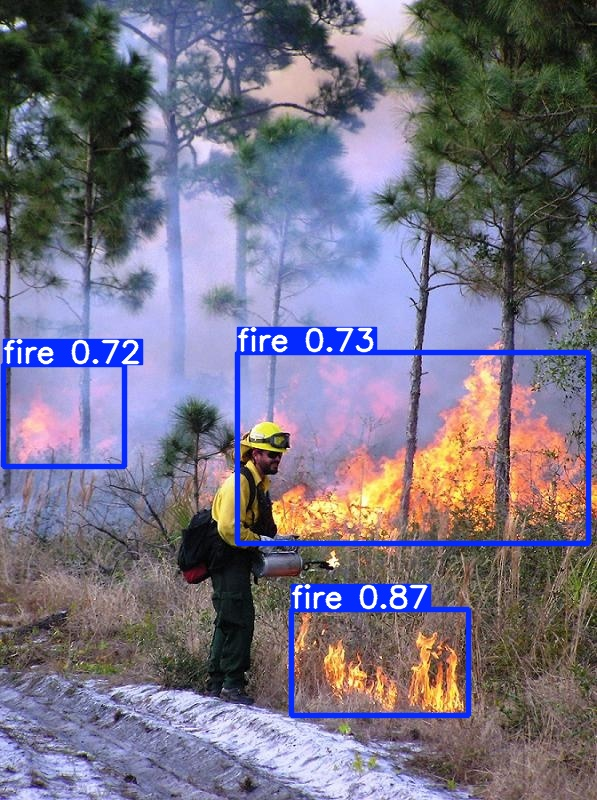

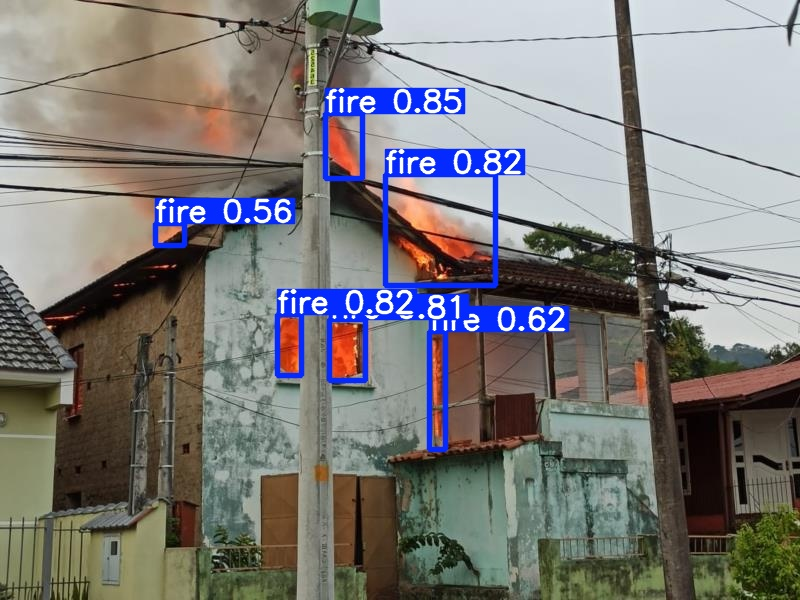

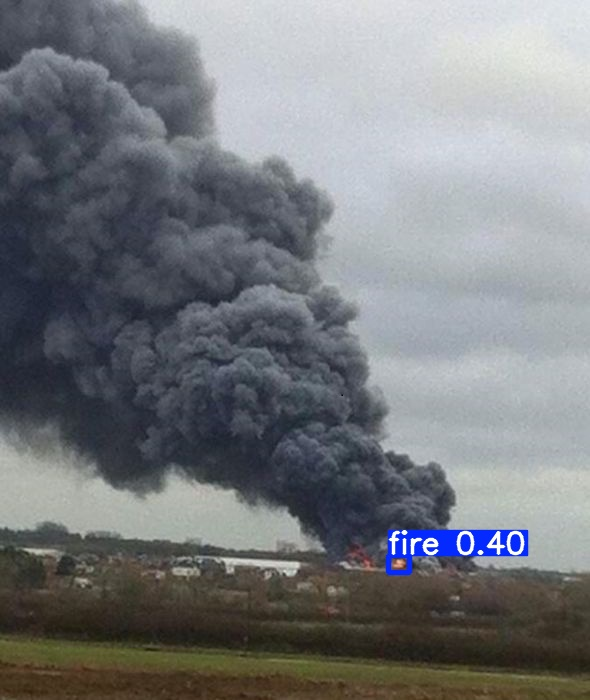

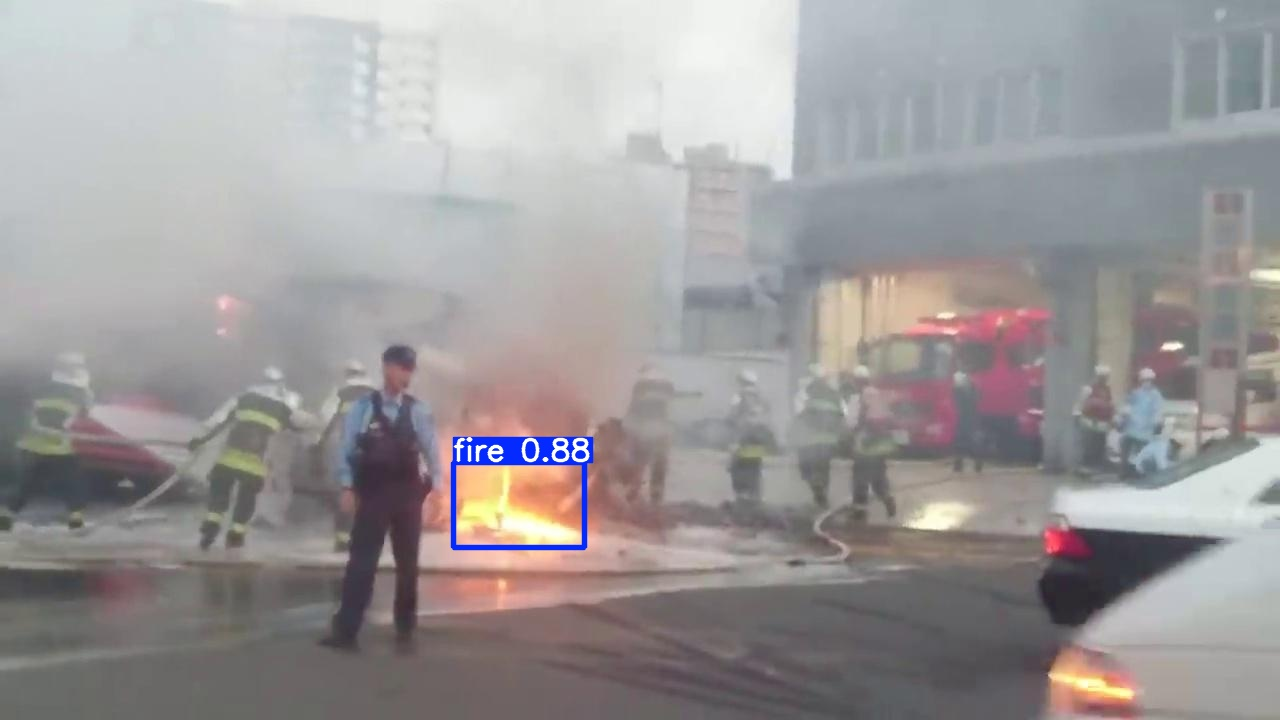

In [ ]:
# Tu dong so sanh mAP de chon mo hinh tot nhat
import os
import pandas as pd

def get_map(exp):
    csv_p = f'runs/train/{exp}/results.csv'
    if os.path.exists(csv_p):
        df = pd.read_csv(csv_p)
        df.columns = [c.strip() for c in df.columns]
        col_map = 'metrics/mAP50' if 'metrics/mAP50' in df.columns else 'metrics/mAP_0.5'
        return df[col_map].max()
    return 0.0

map_exp1 = get_map('exp1_baseline')
map_exp2 = get_map('exp2_tuning')

print(f"mAP@0.5 Exp 1: {map_exp1 * 100:.2f}% | Exp 2: {map_exp2 * 100:.2f}%")

if map_exp2 >= map_exp1 and os.path.exists('runs/train/exp2_tuning/weights/best.pt'):
    best_model_path = 'runs/train/exp2_tuning/weights/best.pt'
    winner = 'Exp 2 (Tuning)'
elif os.path.exists('runs/train/exp1_baseline/weights/best.pt'):
    best_model_path = 'runs/train/exp1_baseline/weights/best.pt'
    winner = 'Exp 1 (Baseline)'
else:
    best_model_path = 'runs/train/exp2_tuning/weights/best.pt'
    winner = 'Exp 2 (Tuning)'

print(f"Mo hinh dat do chinh xac cao nhat: {winner}")
print(f"Duong dan mo hinh: {best_model_path}")

# Danh gia dinh luong tren tap test (task=test)
!python val.py --weights {best_model_path} --data fire.yaml --task test --img 640 --conf 0.25 --name eval_test_set

# Suy luan tren tap anh test (Inference)
!python detect.py --weights {best_model_path} --source /content/dataset_clean/test/images --img 640 --conf 0.35 --name detect_test_samples

import glob
from IPython.display import Image, display
sample_preds = glob.glob('runs/detect/detect_test_samples/*.jpg')[:6]
for p in sample_preds:
    display(Image(filename=p, width=500))


### [Buoc 10] Dong goi va sao luu toan bo Model va Bao cao ve Google Drive
Luu ca 2 model: exp1_best.pt va exp2_best.pt, gan best.pt mac dinh, luu toan bo bieu do danh gia, du lieu test va nen thanh file ZIP tren Google Drive.


In [ ]:
import os
import shutil
import glob

# Thu muc luu tru tren Google Drive
DEPLOY_DIR = '/content/drive/MyDrive/fire_app_deployment'
os.makedirs(DEPLOY_DIR, exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/models", exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/test_samples", exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/eval_results", exist_ok=True)

print("1. Dang luu CA 2 MODEL (.pt) vao thu muc models/...")

# Luu model Thi nghiem 1 (Baseline)
if os.path.exists('runs/train/exp1_baseline/weights/best.pt'):
    shutil.copy('runs/train/exp1_baseline/weights/best.pt', f"{DEPLOY_DIR}/models/exp1_best.pt")
    print("   - Da luu model Exp 1 thanh cong: exp1_best.pt")

# Luu model Thi nghiem 2 (Tuning)
if os.path.exists('runs/train/exp2_tuning/weights/best.pt'):
    shutil.copy('runs/train/exp2_tuning/weights/best.pt', f"{DEPLOY_DIR}/models/exp2_best.pt")
    print("   - Da luu model Exp 2 thanh cong: exp2_best.pt")

# Gan model tot nhat lam best.pt mac dinh
shutil.copy(best_model_path, f"{DEPLOY_DIR}/models/best.pt")
print(f"   - File best.pt mac dinh duoc gan tu: {best_model_path}")

print("\n2. Dang luu toan bo bao cao va bieu do danh gia (Exp 1 va Exp 2)...")
for exp in ['exp1_baseline', 'exp2_tuning']:
    exp_dir = f"runs/train/{exp}"
    if os.path.exists(exp_dir):
        for f in ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png', 'results.csv']:
            src = os.path.join(exp_dir, f)
            if os.path.exists(src):
                shutil.copy(src, f"{DEPLOY_DIR}/eval_results/{exp}_{f}")
print("   - Da luu xong cac bieu do ket qua vao eval_results/")

print("\n3. Dang luu anh va video kiem thu...")
test_samples = glob.glob('/content/dataset_clean/test/images/*.*')[:10]
for s in test_samples:
    shutil.copy(s, f"{DEPLOY_DIR}/test_samples/{os.path.basename(s)}")

drive_video = '/content/drive/MyDrive/input.mp4'
if os.path.exists(drive_video):
    shutil.copy(drive_video, f"{DEPLOY_DIR}/test_samples/test_video.mp4")

with open(f"{DEPLOY_DIR}/classes.txt", 'w', encoding='utf-8') as f:
    f.write("fire\n")

print("\n4. Dang nen thanh file ZIP tren Google Drive...")
shutil.make_archive('/content/drive/MyDrive/fire_app_deployment', 'zip', DEPLOY_DIR)

print("\nHOAN TAT SAO LUU!")
print(f"Thu muc tren Google Drive: {DEPLOY_DIR}")
print(f"File nen tai ve may tinh: /content/drive/MyDrive/fire_app_deployment.zip")


1. Dang luu CA 2 MODEL (.pt) vao thu muc models/...
   - Da luu model Exp 1 thanh cong: exp1_best.pt
   - Da luu model Exp 2 thanh cong: exp2_best.pt
   - File best.pt mac dinh duoc gan tu: runs/train/exp1_baseline/weights/best.pt

2. Dang luu toan bo bao cao va bieu do danh gia (Exp 1 va Exp 2)...
   - Da luu xong cac bieu do ket qua vao eval_results/

3. Dang luu anh va video kiem thu...

4. Dang nen thanh file ZIP tren Google Drive...

HOAN TAT SAO LUU!
Thu muc tren Google Drive: /content/drive/MyDrive/fire_app_deployment
File nen tai ve may tinh: /content/drive/MyDrive/fire_app_deployment.zip
